# 03 · Comparación entre países

Equivale a la sección 6 del paper ancla. Responde las preguntas 3 y 4: evolución por país y
comparación entre países de distinto tamaño.

**Pendiente:** la normalización por millón de habitantes (PMI) requiere los datos de población de
UN Data, que todavía no se extraen. Ver `extract/indicators.py` en `docs/PLAN.md`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from astroca.config import get_loader
from astroca.storage import DataStore
from astroca import viz

viz.aplicar_estilo()

loader = get_loader()
store = DataStore(loader.settings().data_dir)

pubs = store.read_latest_raw("publications")
aff = store.read_latest_processed("author_affiliations")
paises = {c.iso3: c.name for c in loader.countries().in_scope()}

print(f"publicaciones: {len(pubs)}   filas autor-afiliacion: {len(aff)}")

publicaciones: 273   filas autor-afiliacion: 1233


## Publicaciones por país

In [2]:
region = aff[aff["iso3"].notna()]

pubs_por_pais = (region.groupby("iso3")["bibcode"].nunique()
                 .sort_values(ascending=False)
                 .rename("publicaciones"))
autores_por_pais = (region.groupby("iso3")["author"].nunique()
                    .rename("autores distintos"))

tabla = pd.concat([pubs_por_pais, autores_por_pais], axis=1).sort_values(
    "publicaciones", ascending=False)
tabla.index = [paises.get(i, i) for i in tabla.index]
display(tabla)

,publicaciones,autores distintos
Costa Rica,155,135
Panama,47,55
Guatemala,37,33
Honduras,14,12
Nicaragua,14,17
El Salvador,12,11
Belice,1,6


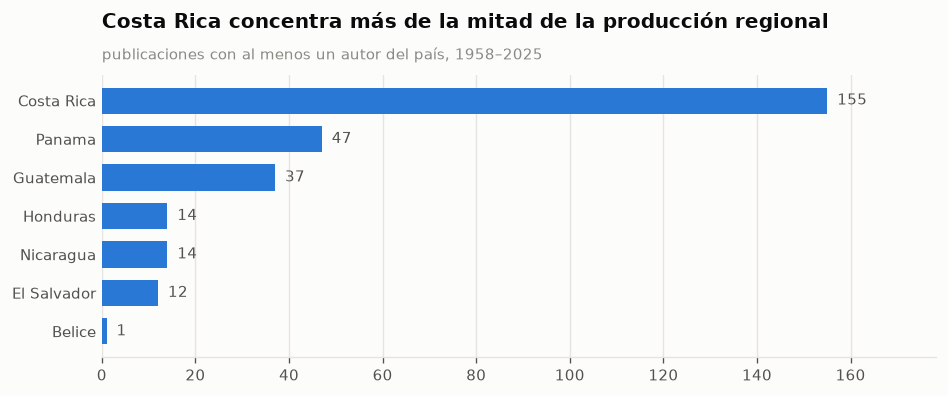

Costa Rica: 55% del total regional
Los tres paises mas pequenos suman 27 publicaciones.


In [3]:
fig, ax = plt.subplots(figsize=(8, 3.4))
viz.barras_horizontales(ax, tabla.index.tolist(), tabla["publicaciones"].tolist())
viz.titulo(ax, "Costa Rica concentra más de la mitad de la producción regional",
           "publicaciones con al menos un autor del país, 1958–2025")
plt.tight_layout()
plt.show()

total = tabla["publicaciones"].sum()
print(f"Costa Rica: {tabla['publicaciones'].iloc[0] / total:.0%} del total regional")
print(f"Los tres paises mas pequenos suman {tabla['publicaciones'].tail(3).sum()} publicaciones.")

## Tamaño de la comunidad: autores distintos por país

El paper ancla define *autor activo* como el que publicó en los últimos 5 años. Aquí se cuenta el
total histórico de autores distintos, que es el límite superior de esa cifra.

**Advertencia:** el conteo no desambigua nombres. Un mismo investigador firmado de dos formas
cuenta doble. Es el siguiente paso en `transform/authors.py`.

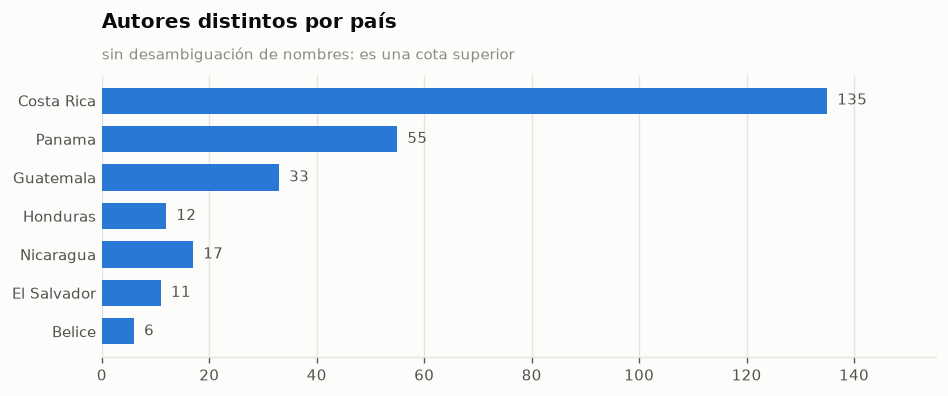

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.4))
viz.barras_horizontales(ax, tabla.index.tolist(), tabla["autores distintos"].tolist())
viz.titulo(ax, "Autores distintos por país",
           "sin desambiguación de nombres: es una cota superior")
plt.tight_layout()
plt.show()

## ¿Qué tan internacional es la producción de cada país?

Proporción de autores del propio país dentro de cada publicación. Un valor bajo significa que los
investigadores de ese país participan sobre todo como coautores en equipos internacionales.

In [5]:
autores_por_pub = aff.groupby("bibcode").size()

filas = []
for iso3 in pubs_por_pais.index:
    del_pais = region[region["iso3"] == iso3].groupby("bibcode").size()
    proporcion = (del_pais / autores_por_pub.reindex(del_pais.index)).dropna()
    filas.append({
        "país": paises.get(iso3, iso3),
        "publicaciones": len(proporcion),
        "% autores locales (mediana)": round(proporcion.median() * 100, 1),
        "publicaciones 100% locales": int((proporcion == 1).sum()),
    })

internacionalizacion = pd.DataFrame(filas).set_index("país")
display(internacionalizacion)

,publicaciones,% autores locales (mediana),publicaciones 100% locales
país,,,
Costa Rica,155,40.0,41
Panama,47,22.2,7
Guatemala,37,25.0,2
Honduras,14,20.0,1
Nicaragua,14,20.0,1
El Salvador,12,41.7,2
Belice,1,100.0,1


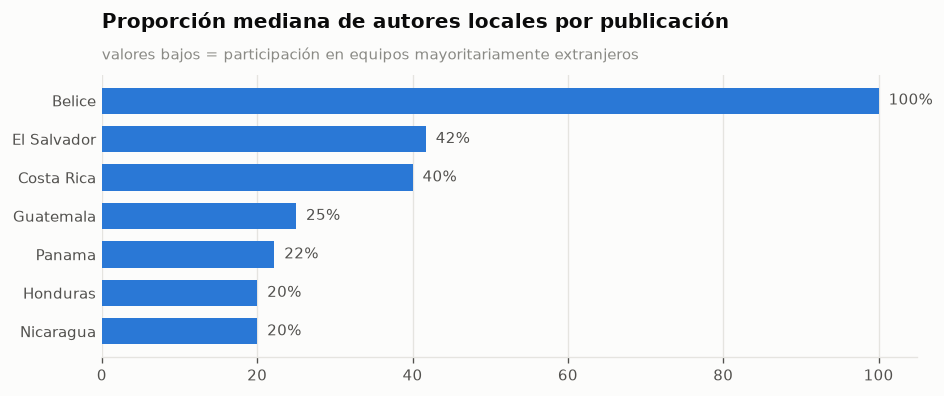

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
orden = internacionalizacion.sort_values("% autores locales (mediana)", ascending=False)
viz.barras_horizontales(ax, orden.index.tolist(),
                        orden["% autores locales (mediana)"].tolist(),
                        formato="{:.0f}%")
ax.set_xlim(0, 105)
viz.titulo(ax, "Proporción mediana de autores locales por publicación",
           "valores bajos = participación en equipos mayoritariamente extranjeros")
plt.tight_layout()
plt.show()